# Plane Wave Scattering from a Sphere and a Cylinder in FDTDX

This notebook sets up a plane wave in vacuum that travels along z and hits two dielectric objects, a sphere and a cylinder, placed side by side. The four sides parallel to the propagation direction (x and y) have periodic boundaries, so the wave is a true plane wave over the whole cross-section. PML absorbers at the top and bottom (z) take up the outgoing waves.

The notebook also compares two plotting functions:

- `fdtdx.plot_setup` draws the bounding box of every object. It does not know whether an object is a sphere, a cube or a cylinder.
- `fdtdx.plot_material` plots the permittivity on the Yee grid, which is the geometry the solver actually uses.

In [2]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pytreeclass as tc
from IPython.display import Video

import fdtdx

%matplotlib inline

## 1. Simulation configuration

`fdtdx.SimulationConfig` sets the simulated time, the grid spacing, the floating point precision and the Courant factor. We also create a JAX random key, which fdtdx expects even when the simulation is deterministic.

In [5]:
# JAX random key
key = jax.random.PRNGKey(seed=42)

# List of all simulation objects (volume, boundaries, source, scatterers, detectors, ...)
object_list = []

config = fdtdx.SimulationConfig(
    time=200e-15,          # total simulated time: 200 fs
    grid=fdtdx.UniformGrid(spacing=100e-9),     # grid spacing: 100 nm
    dtype=jnp.float32,
    courant_factor=0.99,
)

## 2. Simulation volume

The `SimulationVolume` is the whole simulation domain, including the boundary layers, which are placed inside its outer cells. Its background material is vacuum here (`permittivity=1.0`, `permeability=1.0`).

In [8]:
volume = fdtdx.SimulationVolume(
    partial_real_shape=(14e-6, 10e-6, 12e-6),  # size in meters (x, y, z)
    material=fdtdx.Material(
        permittivity=1.0,
        permeability=1.0,
    ),
)
object_list.append(volume)

# Constraints connect objects to each other / to the volume. We build this
# list incrementally as we add more objects below.
constraints = []

## 3. Boundary conditions: periodic in x and y, PML in z

`fdtdx.BoundaryConfig.from_uniform_bound` creates the same boundary type on all six faces. Passing `override_types` changes individual faces. We use PML (10 grid cells, i.e. 1 µm) as the default and set the four faces normal to x and y to `"periodic"`.

With periodic boundaries, a wave that leaves through one face re-enters through the opposite one, so the domain acts as one unit cell of an infinite lattice. A plane wave then stays uniform in x and y. The objects we add below are repeated with the period of the box, 14 µm in x and 10 µm in y.

In [11]:
bound_cfg = fdtdx.BoundaryConfig.from_uniform_bound(
    thickness=10,
    boundary_type="pml",
    override_types={
        "min_x": "periodic",
        "max_x": "periodic",
        "min_y": "periodic",
        "max_y": "periodic",
    },
)
bound_dict, bound_constraints = fdtdx.boundary_objects_from_config(bound_cfg, volume)

object_list.extend(bound_dict.values())
constraints.extend(bound_constraints)

## 4. Plane wave source

`fdtdx.UniformPlaneSource` emits a wave with uniform amplitude over its aperture (`fdtdx.GaussianPlaneSource` has a Gaussian profile instead). We place it near the top of the volume, propagating along -z, with the electric field polarized along x.

The side boundaries are periodic, so the source has to cover the full x/y cross-section of the volume, which we do with `same_size`. A smaller source would have edges that diffract, and the wave would no longer be a plane wave.

In [14]:
source = fdtdx.UniformPlaneSource(
    partial_grid_shape=(None, None, 1),      # a single-cell-thick sheet in z
    fixed_E_polarization_vector=(1, 0, 0),   # Ex-polarized
    wave_character=fdtdx.WaveCharacter(wavelength=1.550e-6),
    direction="-",                           # propagates toward -z
    name="Source",
)
object_list.append(source)

constraints.extend([
    source.same_size(volume, axes=(0, 1)),   # cover the full x/y cross-section
    source.place_relative_to(
        volume,
        axes=(0, 1, 2),
        own_positions=(0, 0, 1),
        other_positions=(0, 0, 1),
        margins=(0, 0, -1.5e-6),  # inset 1.5 µm from the top of the volume
    ),
])

## 5. Sphere and cylinder

Both objects use the same dielectric (`permittivity=4.0`, refractive index n = 2), so any difference in the scattering comes from the geometry alone.

- `fdtdx.Sphere` needs a `radius`. Its bounding box is `(2r, 2r, 2r)`.
- `fdtdx.Cylinder` needs a `radius` and an `axis` (0 = x, 1 = y, 2 = z) along which it extends. We use `axis=1`, so the cylinder lies perpendicular to the propagation direction (z) and to the line connecting the two objects (x). Its circular cross-section is in the x-z plane. `same_size(volume, axes=(1,))` stretches it over the whole y extent, and since y is periodic it acts as an infinitely long rod.

Unlike `UniformMaterialObject`, both objects take a `materials` dictionary together with a `material_name`, not a single `material`.

In [17]:
dielectric = fdtdx.Material(permittivity=4.0)  # n = 2, used for both objects

sphere = fdtdx.Sphere(
    radius=1.2e-6,
    materials={"dielectric": dielectric},
    material_name="dielectric",
    name="Sphere",
    color=fdtdx.colors.PINK,
)
object_list.append(sphere)
constraints.append(
    sphere.place_relative_to(
        volume,
        axes=(0, 1, 2),
        own_positions=(0, 0, 0),
        other_positions=(0, 0, 0),
        margins=(-3.0e-6, 0.0, 0.0),  # shift 3 µm in -x from the volume center
    )
)

cylinder = fdtdx.Cylinder(
    radius=1.2e-6,
    axis=1,  # extends along y
    materials={"dielectric": dielectric},
    material_name="dielectric",
    name="Cylinder",
)
object_list.append(cylinder)
constraints.append(
    cylinder.place_relative_to(
        volume,
        axes=(0, 1, 2),
        own_positions=(0, 0, 0),
        other_positions=(0, 0, 0),
        margins=(3.0e-6, 0.0, 0.0),  # shift 3 µm in +x from the volume center
    )
)
constraints.append(
    cylinder.same_size(volume, axes=(1,))  # stretch the cylinder across all of y
)

## 6. Energy detector for the video

`fdtdx.EnergyDetector` records the electromagnetic energy. With `as_slices=True` it stores only the 2D slices needed for plotting, not the full 3D volume at every step, which saves memory. `interval=3` records every third time step.

In [20]:
video_energy_detector = fdtdx.EnergyDetector(
    name="Video",
    as_slices=True,
    switch=fdtdx.OnOffSwitch(interval=3),  # record every 3rd time step
    exact_interpolation=True,
    num_video_workers=8,
)
object_list.append(video_energy_detector)
constraints.extend(video_energy_detector.same_position_and_size(volume))

## 7. Resolving the constraints

`fdtdx.place_objects` turns the objects and constraints into concrete grid positions and shapes, and allocates the arrays (permittivity, fields, ...).

In [23]:
key, subkey = jax.random.split(key)
objects, arrays, params, config, _ = fdtdx.place_objects(
    object_list=object_list,
    config=config,
    constraints=constraints,
    key=subkey,
)

print(tc.tree_summary(arrays, depth=1))

┌───────────────────────────┬──────────────────┬──────────┬────────┐
│Name                       │Type              │Count     │Size    │
├───────────────────────────┼──────────────────┼──────────┼────────┤
│.fields                    │FieldState        │11,200,000│42.72MB │
├───────────────────────────┼──────────────────┼──────────┼────────┤
│.inv_permittivities        │f32[1,140,100,120]│1,680,000 │6.41MB  │
├───────────────────────────┼──────────────────┼──────────┼────────┤
│.inv_permeabilities        │float             │1         │        │
├───────────────────────────┼──────────────────┼──────────┼────────┤
│.detector_states           │dict              │14,980,000│57.14MB │
├───────────────────────────┼──────────────────┼──────────┼────────┤
│.recording_state           │NoneType          │          │        │
├───────────────────────────┼──────────────────┼──────────┼────────┤
│.electric_conductivity     │NoneType          │          │        │
├───────────────────────────┼─────

## 8. `plot_setup`: bounding boxes

`fdtdx.plot_setup` shows the XY, XZ and YZ cross-sections of the volume, with every object drawn as a rectangle, its bounding box.

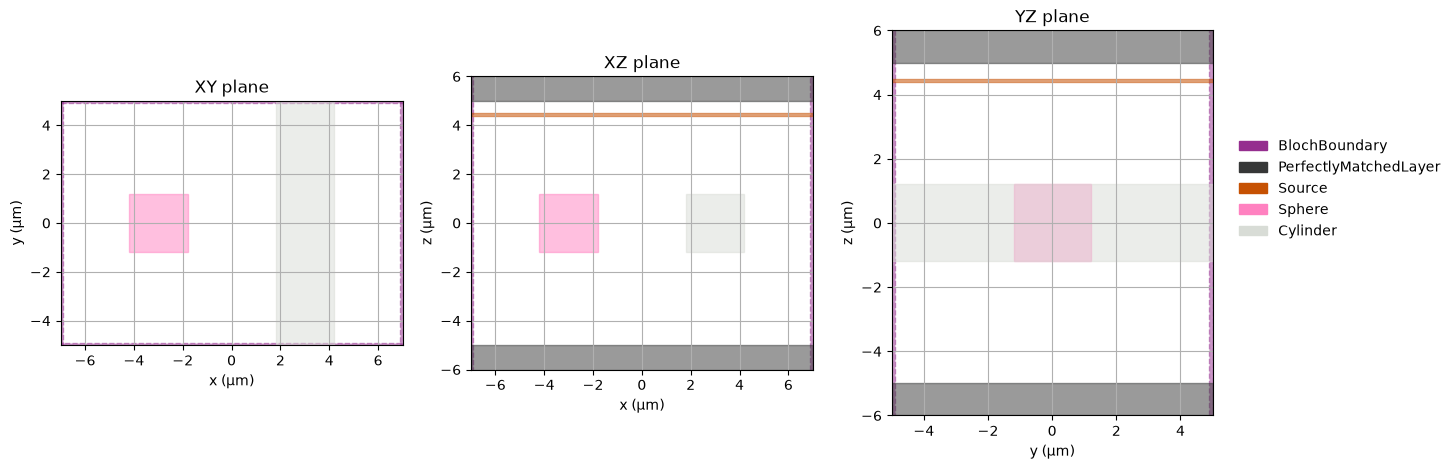

In [26]:
fig = fdtdx.plot_setup(
    config=config,
    objects=objects,
    exclude_object_list=[video_energy_detector],
)
plt.show()

In the XZ plane the sphere and the cylinder are two identical squares, since both bounding boxes are 2.4 µm wide in x and z. They only differ in the XY and YZ planes, where the cylinder's box covers the full y range.

`plot_setup` only knows `partial_real_shape` and `partial_real_position`, so a sphere and a cube would be drawn the same way. That is enough to check where the objects are and whether they overlap, but it says nothing about their actual shape.

The source covers the whole x/y cross-section. The periodic faces appear as thin `BlochBoundary` lines at the edges, because fdtdx implements a periodic boundary as a Bloch boundary with zero Bloch vector.

## 9. `plot_material`: the voxelized geometry

`fdtdx.plot_material` plots the permittivity that was written into the simulation grid, i.e. what the solver actually sees. The slice `positions` are given in meters relative to the center of the volume. We call it twice: once with the slices through the center of the sphere (x = -3 µm), and once through the center of the cylinder (x = +3 µm).

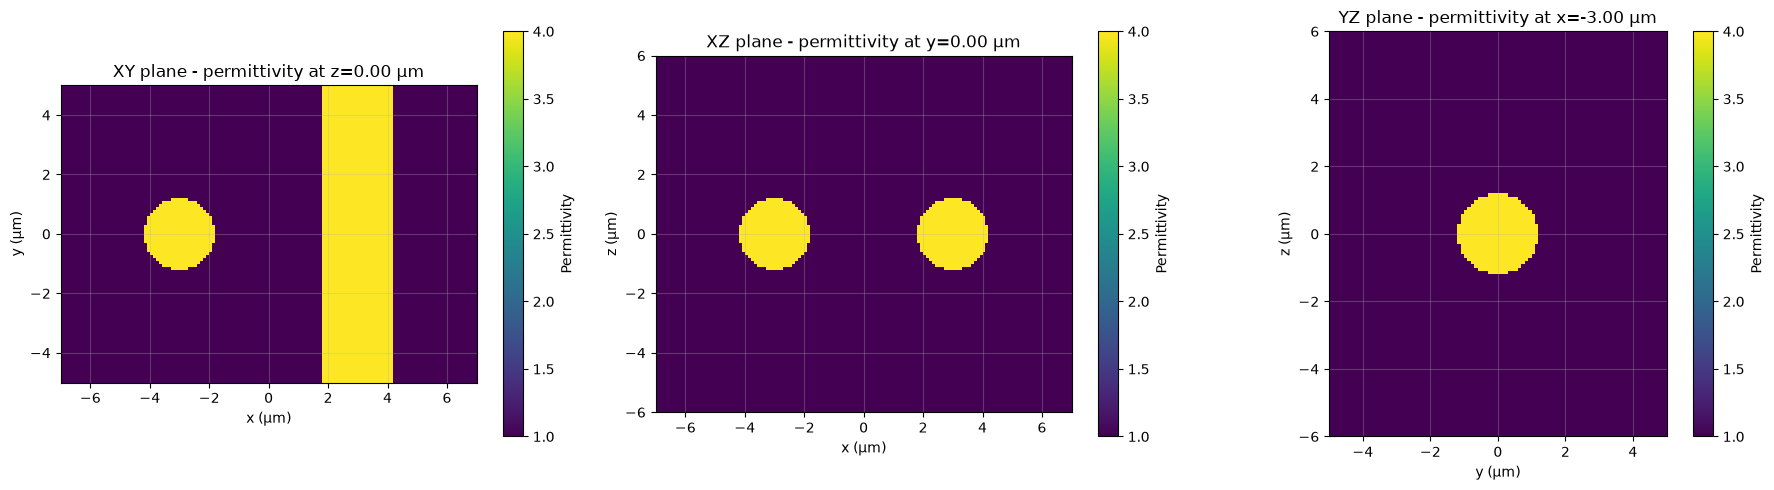

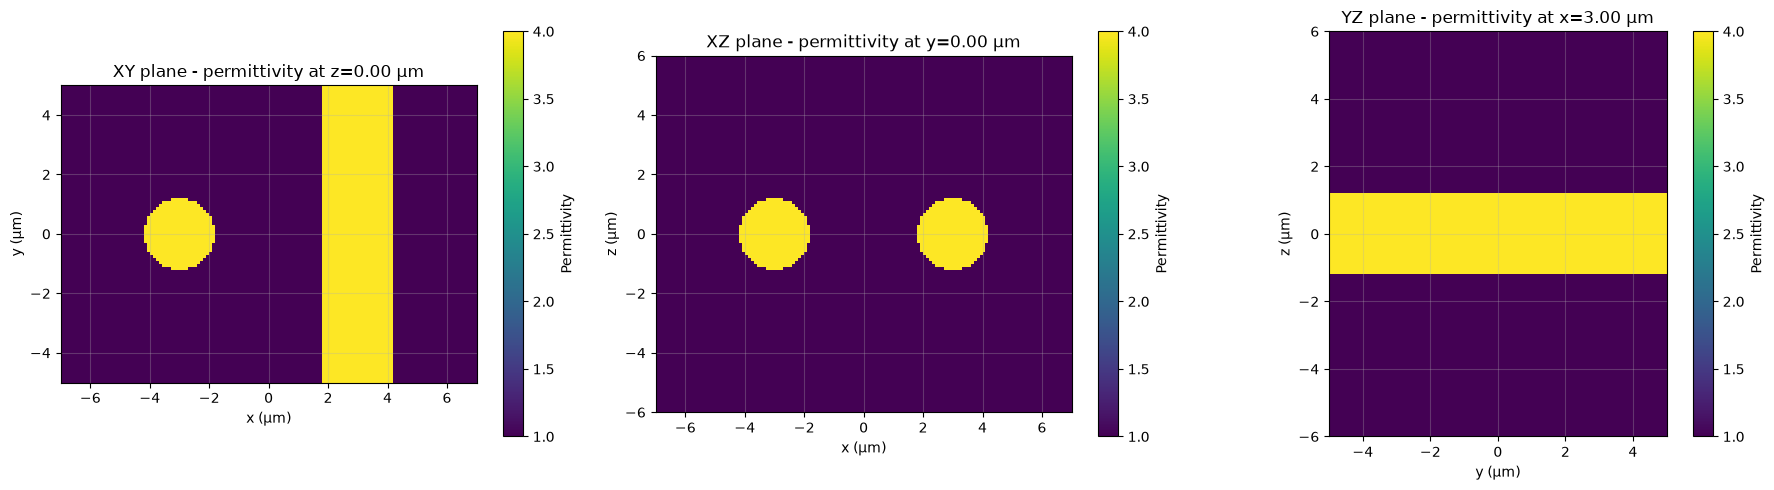

In [30]:
# slices through the center of the sphere
fig = fdtdx.plot_material(
    config=config,
    arrays=arrays,
    positions=(-3.0e-6, 0.0, 0.0),
)
plt.show()

# slices through the center of the cylinder
fig = fdtdx.plot_material(
    config=config,
    arrays=arrays,
    positions=(3.0e-6, 0.0, 0.0),
)
plt.show()

Now the two objects look different:

- Through the sphere (first figure), the sphere is a filled circle in all three planes (XY, XZ and YZ).
- Through the cylinder (second figure), the cylinder is a circle only in the XZ plane, which is perpendicular to its axis. In the XY and YZ planes it is a band over the full y range, since it is extruded along y.

`plot_setup` draws bounding boxes and cannot tell a sphere from a cube. `plot_material` shows the material as it is discretized on the Yee grid.

## 10. Running the simulation

A simulation takes two steps. `fdtdx.apply_params` applies the design parameters (there are none here), and `fdtdx.run_fdtd` runs the time-stepping loop. We wrap both in `sim_fn` and compile it with `jax.jit`.

In [34]:
def sim_fn(
    params: fdtdx.ParameterContainer,
    arrays: fdtdx.ArrayContainer,
    key: jax.Array,
):
    arrays, new_objects, _ = fdtdx.apply_params(arrays, objects, params, key)

    final_state = fdtdx.run_fdtd(
        arrays=arrays,
        objects=new_objects,
        config=config,
        key=key,
    )
    _, arrays = final_state
    return arrays

In [36]:
start_time = time.time()
jitted_sim_fn = jax.jit(sim_fn).lower(params, arrays, key).compile()
print(f"Compilation time: {time.time() - start_time:.2f} seconds")

Compilation time: 0.30 seconds


In [38]:
start_time = time.time()
new_arrays = jitted_sim_fn(params, arrays, subkey)
print(f"Simulation runtime: {time.time() - start_time:.2f} seconds")

FDTD (checkpointed):   0%|                           | 0/1049 [00:00<?, ?step/s]

Simulation runtime: 10.04 seconds


## 11. Visualizing the result

The recorded energy gives a video of the wave traveling along -z and scattering off the sphere and the cylinder. Away from the objects the energy is uniform in x and y, as expected for a plane wave.

In [41]:
video_path = objects["Video"].draw_plot(new_arrays.detector_states["Video"])
Video(list(video_path.values())[0], embed=True, width=720)